# Architecture 1 — Decoder with a **copy (pointer) mechanism** and **multi-token prediction**

**Starting point:** our decoder A (RoPE, RMSNorm, SwiGLU — LLaMA-style, written by hand). Per the course clarification, a re-implementation alone is not enough, so we add **two architectural changes of our own**, each motivated by something we observed, and test each with an **ablation**.

### Change 1 — Copy (pointer) mechanism

**Observation:** legal continuations constantly reuse exact strings from the prompt — party names ("Hari Singh & Ors."), section numbers ("Section 420 read with 120B IPC"), case citations. A normal LM must _regenerate_ these from its vocabulary.
**Idea** (inspired by pointer-generator networks, See et al. 2017, designed for summarisation; we adapt it to a decoder-only LM): at every position the model has two ways to produce the next token:

- **generate** it from the vocabulary (the usual softmax), or
- **copy** a token that appeared earlier in the context, chosen by a small _copy attention_ over all previous positions.

A learned **gate** g ∈ (0,1) mixes them: `p(next) = g · p_vocab + (1 − g) · p_copy`. The gate is interpretable: we can measure _which_ tokens the model prefers to copy.

### Change 2 — Multi-token prediction (MTP)

**Observation:** the task is to write 128 coherent words; the baseline fell into loops (`27/87, 27/87, …`). Next-token training only rewards the very next step.
**Idea** (inspired by Gloeckle et al. 2024): an extra transformer block on top of the trunk predicts the token **two steps ahead**; its loss (weight 0.3) is added during training, pushing the shared trunk to encode _where the text is going_. The extra block is **used only in training** and dropped at inference (no generation cost).

### Ablation plan (same 40M tokens, same chunks, same settings)

| run | copy | MTP |
| --- | ---- | --- |
| a   | –    | –   |
| b   | ✓    | –   |
| c   | –    | ✓   |
| d   | ✓    | ✓   |

Compared on next-token validation loss and bits/char (same tokenizer → valid). The best configuration then gets the full 200M run + submission.

**How to use this notebook:** set `USE_COPY`, `USE_MTP` and `ABLATION` in cell 0. `ABLATION = True` → 40M tokens, training + validation only (no generation). Each configuration gets its own folder, so runs never overwrite each other. The last cell prints the ablation table from whatever runs exist.

**Rules followed:** progress bars · checkpoints + resume · load instead of retrain · every result cached.


## 0. Setup and configuration

All experiment settings live in `CFG`. The run folder name comes from `RUN_NAME`, so a new experiment = a new `RUN_NAME` (otherwise the notebook finds the old model and skips training).


In [15]:
import os, sys, json, math, time, re, unicodedata, random, zipfile, subprocess
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from tqdm.auto import tqdm
from tokenizers import Tokenizer

SMOKE_TEST = False          # True = quick pipeline test (both changes ON). Set False for real runs.
USE_COPY   = True          # change 1: copy (pointer) mechanism
USE_MTP    = False          # change 2: multi-token prediction head (training only)
ABLATION   = False          # True = 40M-token ablation run (train + validate only); False = full 200M run + submission

PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / ".gitignore").exists():
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise FileNotFoundError("Project root with .gitignore not found")
    PROJECT_ROOT = PROJECT_ROOT.parent

CFG = dict(
    arch="A2",
    use_copy=None, use_mtp=None, copy_dim=128, mtp_weight=0.3,
    # model
    vocab_size=32_000, d_model=640, n_layers=10, n_heads=10, mlp_hidden=1728, max_seq_len=1536,
    # data (shared by all architectures)
    train_tokens=200_000_000, mix={"sc": 0.7, "tribunals": 0.3}, eval_chunks=256,
    # optimisation
    micro_batch=2, grad_accum=5, lr=3e-4, min_lr=3e-5, warmup_steps=300,
    weight_decay=0.1, grad_clip=1.0, betas=(0.9, 0.95),
    # bookkeeping
    log_every=50, eval_every=500, ckpt_every=500, snapshot_every=1500, seed=42,
)
CFG.update(use_copy=USE_COPY, use_mtp=USE_MTP)
if ABLATION:
    CFG.update(train_tokens=40_000_000, eval_every=250, ckpt_every=250, snapshot_every=10**9)
if SMOKE_TEST:
    CFG.update(train_tokens=3_000_000, eval_every=50, ckpt_every=50, snapshot_every=100, eval_chunks=32)

RUN_NAME = (f"{CFG['arch']}_copy{int(USE_COPY)}_mtp{int(USE_MTP)}_d{CFG['d_model']}_L{CFG['n_layers']}"
            f"_sc70tr30_{CFG['train_tokens']//1_000_000}M" + ("_SMOKE" if SMOKE_TEST else ""))
RUN_DIR     = PROJECT_ROOT / "checkpoints" / "phase1" / RUN_NAME
TOKENS_DIR  = PROJECT_ROOT / "data" / "tokens_bpe32k"
PLAN_DIR    = PROJECT_ROOT / "data" / "train_plans"
EVAL_DIR    = PROJECT_ROOT / "data" / "local_eval"
TOK_PATH    = PROJECT_ROOT / "data" / "tokenizer" / "bpe32k.json"
EVAL_SCRIPT = PROJECT_ROOT / "scripts" / "evaluate_phase1.py"
EXP_LOG     = PROJECT_ROOT / "experiments" / "experiments.jsonl"
for d in (RUN_DIR, PLAN_DIR, EXP_LOG.parent):
    d.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP_DTYPE = torch.bfloat16 if (device.type == "cuda" and torch.cuda.is_bf16_supported()) else torch.float32
random.seed(CFG["seed"]); np.random.seed(CFG["seed"]); torch.manual_seed(CFG["seed"])
print("Run      :", RUN_NAME)
print("Run dir  :", RUN_DIR)
print("Device   :", device, "| precision:", AMP_DTYPE)

Run      : A2_copy1_mtp0_d640_L10_sc70tr30_200M
Run dir  : c:\Users\Atharva\Desktop\Course Sem 1\LLM\Capstone Project\checkpoints\phase1\A2_copy1_mtp0_d640_L10_sc70tr30_200M
Device   : cuda | precision: torch.bfloat16


## 1. Cleaning function (identical copy of `02_tokenizer` / `03_prepare_data`)

Used on every prompt before generation, so prompts look exactly like the training text.


In [16]:
SIGNATURE_RE = re.compile(r"Signature Not Verified.{0,150}?IST(\s*Reason:)?", flags=re.DOTALL)
ASCII_MAP = str.maketrans({
    "\u2018": "'", "\u2019": "'", "\u201a": "'", "\u201b": "'",
    "\u201c": '"', "\u201d": '"', "\u201e": '"', "\u201f": '"',
    "\u2013": "-", "\u2014": "-", "\u2015": "-", "\u2212": "-",
    "\u2026": "...",
    "\u00a0": " ", "\u2009": " ", "\u200b": "",
    "\u00ad": "",
    "\u20b9": "Rs.", "\u00a7": "S.", "\u2022": "-", "\u00b7": ".",
})
def clean_text(text):
    text = SIGNATURE_RE.sub(" ", text)
    text = text.translate(ASCII_MAP)
    text = unicodedata.normalize("NFKD", text)
    text = text.encode("ascii", "ignore").decode("ascii")
    return " ".join(text.split())

## 2. Tokenizer and data

**Chunks.** A training example is `max_seq_len + 1 = 1537` consecutive tokens: the model reads the first 1536 (`x`) and must predict the last 1536 (`y`, the same tokens shifted by one). In our own loop we do this shift ourselves — no library hides it.

**The training plan (shared by all architectures).** Each source's token file is divided into non-overlapping 1537-token chunks. We randomly pick 70% of the needed chunks from SC and 30% from Tribunals (seeded), shuffle them, and save the list of `(source, chunk index)` pairs to `data/train_plans/`. Every architecture notebook loads the **same plan**, so all models see exactly the same tokens in exactly the same order. Random chunks come from the _whole_ file (not just the start), which avoids the "files are sorted by year" bias.

**Reading data.** `np.memmap` opens the multi-GB `.bin` files without loading them into RAM; each batch reads just its few chunks from disk.

**Validation chunks.** A fixed set of SC validation chunks, evenly spaced through `sc_val.bin`. SC validation is closest to the test prompts. Same set for every architecture.


In [17]:
tokenizer = Tokenizer.from_file(str(TOK_PATH))
EOS_ID, PAD_ID = tokenizer.token_to_id("<|endoftext|>"), tokenizer.token_to_id("<pad>")
assert tokenizer.get_vocab_size() == CFG["vocab_size"]

CHUNK = CFG["max_seq_len"] + 1
SOURCES = list(CFG["mix"])                                  # ["sc", "tribunals"]; index = source id
train_mm = {s: np.memmap(TOKENS_DIR / f"{s}_train.bin", dtype=np.uint16, mode="r") for s in SOURCES}
sc_val   = np.memmap(TOKENS_DIR / "sc_val.bin", dtype=np.uint16, mode="r")

tokens_per_step = CFG["micro_batch"] * CFG["grad_accum"] * CFG["max_seq_len"]
total_steps     = CFG["train_tokens"] // tokens_per_step
n_chunks_needed = total_steps * CFG["micro_batch"] * CFG["grad_accum"]

mix_tag = "_".join(f"{s}{int(f*100)}" for s, f in CFG["mix"].items())
PLAN_PATH = PLAN_DIR / f"plan_{mix_tag}_{CFG['train_tokens']//1_000_000}M_ctx{CFG['max_seq_len']}_seed{CFG['seed']}.npy"
if PLAN_PATH.exists():
    plan = np.load(PLAN_PATH)
    print("[cache] loaded training plan", PLAN_PATH.name)
else:
    rng = np.random.default_rng(CFG["seed"])
    parts = []
    for sid, (s, frac) in enumerate(CFG["mix"].items()):
        n_avail = len(train_mm[s]) // CHUNK
        n_take  = int(round(n_chunks_needed * frac))
        assert n_take <= n_avail, f"not enough {s} data"
        idx = rng.choice(n_avail, size=n_take, replace=False)
        parts.append(np.stack([np.full(n_take, sid), idx], axis=1))
    plan = np.concatenate(parts)
    rng.shuffle(plan)                                        # mix sources within every batch
    plan = plan[:n_chunks_needed]
    np.save(PLAN_PATH, plan)
    print("Saved training plan", PLAN_PATH.name)

n_val_avail = len(sc_val) // CHUNK
val_idx_small = np.linspace(0, n_val_avail - 1, CFG["eval_chunks"]).astype(int)   # periodic checks
val_idx_full  = np.arange(n_val_avail)                                             # final measurement

def get_chunk(mm, i):
    return torch.from_numpy(mm[i * CHUNK:(i + 1) * CHUNK].astype(np.int64))

def get_batch(step, accum_i):
    start = (step * CFG["grad_accum"] + accum_i) * CFG["micro_batch"]
    rows = plan[start:start + CFG["micro_batch"]]
    batch = torch.stack([get_chunk(train_mm[SOURCES[s]], i) for s, i in rows])
    batch = batch.to(device, non_blocking=True)
    return batch[:, :-1], batch[:, 1:], batch[:, 2:]        # x, next token y, token-after-next y2 (for MTP)

print(f"Tokens per step: {tokens_per_step:,} | total steps: {total_steps:,} | chunks: {len(plan):,}")
print("Source share in plan:", {s: f"{(plan[:,0]==i).mean():.2f}" for i, s in enumerate(SOURCES)})
print(f"SC validation chunks: {n_val_avail:,} available, {len(val_idx_small)} used for periodic checks")

[cache] loaded training plan plan_sc70_tribunals30_200M_ctx1536_seed42.npy
Tokens per step: 15,360 | total steps: 13,020 | chunks: 130,200
Source share in plan: {'sc': '0.70', 'tribunals': '0.30'}
SC validation chunks: 1,833 available, 256 used for periodic checks


## 3. The model: decoder A + copy mechanism + MTP head

**Copy mechanism, in detail.** After the last block we have a hidden vector `h_t` per position.

- copy query `q_t = W_q h_t`, copy key `k_j = W_k h_j` (128 dims each); score `q_t · k_j / √128` for every earlier position `j ≤ t`; softmax → copy attention `a_tj` (how much position t wants to copy the token at position j).
- gate `g_t = sigmoid(w · h_t + b)`, initialised with b = 2 → g ≈ 0.88, i.e. "mostly generate" at the start.
- `p(y) = g_t · softmax(logits_t)[y] + (1 − g_t) · Σ_j a_tj · [x_j = y]`

**Training trick (memory):** we never build the full copy distribution over 32,000 tokens. For the loss we only need the probability of the _correct_ token: `Σ_j a_tj · [x_j = y_t]` = attention mass on earlier positions holding the target token — a (T × T) comparison, cheap. `p_vocab[y]` comes from `exp(logit_y − logsumexp(logits))`. Loss = −log p(y), computed in float32.
No leakage: position t predicts x\_{t+1} but can only copy x_j with j ≤ t.

**MTP head.** One extra `Block` (same design as the trunk's) reads the trunk's output and predicts `x_{t+2}` through the _shared_ final norm-style layer and the tied output matrix. Total loss = next-token loss + 0.3 × two-ahead loss. Dropped at inference.

**Parameter counts:** copy adds ~0.16M (2 × 640 × 128 + gate). MTP adds one block (~4.9M) used only during training. The inference model stays ~70.2M.

Shared blocks (unchanged from A):

**RMSNorm** — rescales each token vector to unit root-mean-square, then multiplies by a learned weight: `x / sqrt(mean(x²) + ε) · w`. Unlike LayerNorm it does not subtract the mean. Computed in float32 for stability, then cast back.

**RoPE** — instead of _adding_ a position vector, each pair of numbers in the query and key vectors is **rotated** by an angle proportional to the token's position (different speed per pair). The dot product of a rotated query and key then depends only on their _distance_. The angles are precomputed once (`cos`, `sin` tables up to 1536 positions).

**Attention** — one linear layer makes queries, keys and values for all 10 heads; RoPE is applied to queries and keys; `F.scaled_dot_product_attention(..., is_causal=True)` computes `softmax(QKᵀ/√d)·V` with the causal mask, using a fast fused kernel. With a **KV cache** (used only during generation) the keys/values of earlier tokens are kept, so each new token only computes its own.

**SwiGLU** — `W2( SiLU(W1·x) ⊙ W3·x )`: one branch decides _how much_ to let through (a gate), the other carries the content. Hidden size 1728 ≈ 8/3 · 640, so its 3 matrices have the same parameter count as a classic 4×-wide MLP.

**Block** (pre-norm, with residuals): `x = x + Attn(RMSNorm(x))`, then `x = x + SwiGLU(RMSNorm(x))`.

**Initialisation** — all weights ~ N(0, 0.02); the two layers that write _into_ the residual stream (attention output, SwiGLU `W2`) use a smaller std 0.02/√(2·layers), so the residual sum doesn't grow with depth (GPT-2 trick).


In [18]:
class RMSNorm(nn.Module):
    def __init__(self, dim, eps=1e-6):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(dim))
    def forward(self, x):
        xf = x.float()
        normed = xf * torch.rsqrt(xf.pow(2).mean(-1, keepdim=True) + self.eps)
        return normed.type_as(x) * self.weight

def rope_tables(head_dim, max_len, base=10000.0):
    inv_freq = 1.0 / (base ** (torch.arange(0, head_dim, 2).float() / head_dim))   # one speed per pair
    angles = torch.outer(torch.arange(max_len).float(), inv_freq)                   # (positions, head_dim/2)
    return angles.cos(), angles.sin()

def apply_rope(x, cos, sin):
    # x: (batch, heads, tokens, head_dim). Rotate the pairs (first half, second half) by the position angle.
    half = x.shape[-1] // 2
    x1, x2 = x[..., :half], x[..., half:]
    cos, sin = cos.to(x.dtype), sin.to(x.dtype)
    return torch.cat([x1 * cos - x2 * sin, x1 * sin + x2 * cos], dim=-1)

class CausalSelfAttention(nn.Module):
    def __init__(self, d_model, n_heads):
        super().__init__()
        self.n_heads, self.head_dim = n_heads, d_model // n_heads
        self.qkv  = nn.Linear(d_model, 3 * d_model, bias=False)
        self.proj = nn.Linear(d_model, d_model, bias=False)
    def forward(self, x, cos, sin, cache=None):
        B, T, D = x.shape
        q, k, v = self.qkv(x).split(D, dim=2)
        q, k, v = (t.view(B, T, self.n_heads, self.head_dim).transpose(1, 2) for t in (q, k, v))
        q, k = apply_rope(q, cos, sin), apply_rope(k, cos, sin)
        past = 0
        if cache is not None:                                  # generation: reuse earlier keys/values
            if "k" in cache:
                past = cache["k"].shape[2]
                k = torch.cat([cache["k"], k], dim=2)
                v = torch.cat([cache["v"], v], dim=2)
            cache["k"], cache["v"] = k, v
        y = F.scaled_dot_product_attention(q, k, v, is_causal=(past == 0 and T > 1))
        return self.proj(y.transpose(1, 2).reshape(B, T, D))

class SwiGLU(nn.Module):
    def __init__(self, d_model, hidden):
        super().__init__()
        self.w1 = nn.Linear(d_model, hidden, bias=False)       # gate branch
        self.w3 = nn.Linear(d_model, hidden, bias=False)       # content branch
        self.w2 = nn.Linear(hidden, d_model, bias=False)       # back to model width
    def forward(self, x):
        return self.w2(F.silu(self.w1(x)) * self.w3(x))

class Block(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.norm1 = RMSNorm(cfg["d_model"]); self.attn = CausalSelfAttention(cfg["d_model"], cfg["n_heads"])
        self.norm2 = RMSNorm(cfg["d_model"]); self.mlp  = SwiGLU(cfg["d_model"], cfg["mlp_hidden"])
    def forward(self, x, cos, sin, cache=None):
        x = x + self.attn(self.norm1(x), cos, sin, cache)
        x = x + self.mlp(self.norm2(x))
        return x

class DecoderLM(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg
        self.tok_emb = nn.Embedding(cfg["vocab_size"], cfg["d_model"])
        self.blocks  = nn.ModuleList(Block(cfg) for _ in range(cfg["n_layers"]))
        self.norm_f  = RMSNorm(cfg["d_model"])
        self.lm_head = nn.Linear(cfg["d_model"], cfg["vocab_size"], bias=False)
        self.lm_head.weight = self.tok_emb.weight               # weight tying
        if cfg["use_copy"]:
            self.copy_q = nn.Linear(cfg["d_model"], cfg["copy_dim"], bias=False)
            self.copy_k = nn.Linear(cfg["d_model"], cfg["copy_dim"], bias=False)
            self.copy_gate = nn.Linear(cfg["d_model"], 1)
        if cfg["use_mtp"]:
            self.mtp_block = Block(cfg)
            self.norm_mtp = RMSNorm(cfg["d_model"])
        cos, sin = rope_tables(cfg["d_model"] // cfg["n_heads"], cfg["max_seq_len"])
        self.register_buffer("cos", cos, persistent=False)      # buffers move with .to(device), not trained
        self.register_buffer("sin", sin, persistent=False)
        self.apply(self._init)
        if cfg["use_copy"]:
            nn.init.zeros_(self.copy_gate.weight); nn.init.constant_(self.copy_gate.bias, 2.0)   # start: g = 0.88
        for blk in list(self.blocks) + ([self.mtp_block] if cfg["use_mtp"] else []):                                 # residual-output layers: smaller init
            for w in (blk.attn.proj.weight, blk.mlp.w2.weight):
                nn.init.normal_(w, std=0.02 / math.sqrt(2 * cfg["n_layers"]))

    @staticmethod
    def _init(m):
        if isinstance(m, (nn.Linear, nn.Embedding)):
            nn.init.normal_(m.weight, std=0.02)

    def forward(self, idx, targets=None, targets2=None, cache=None, start_pos=0, return_hidden=False):
        T = idx.shape[1]
        cos, sin = self.cos[start_pos:start_pos + T], self.sin[start_pos:start_pos + T]
        x = self.tok_emb(idx)
        for i, blk in enumerate(self.blocks):
            x = blk(x, cos, sin, None if cache is None else cache[i])
        trunk = x
        h = self.norm_f(trunk)
        if targets is None:                                     # generation: last position's logits (+ hidden states for copy)
            logits = self.lm_head(h[:, -1, :]).float()
            return (logits, h) if return_hidden else logits
        logits = self.lm_head(h)
        if self.cfg["use_copy"]:
            loss1, copy_frac = self.copy_nll(h, logits, idx, targets)
        else:
            loss1 = F.cross_entropy(logits.float().view(-1, logits.size(-1)), targets.reshape(-1))
            copy_frac = None
        loss2 = None
        if self.cfg["use_mtp"] and targets2 is not None:
            h2 = self.norm_mtp(self.mtp_block(trunk, cos, sin))
            logits2 = self.lm_head(h2[:, :-1])                  # position t predicts token t+2 (last position has no target)
            loss2 = F.cross_entropy(logits2.float().reshape(-1, logits2.size(-1)), targets2.reshape(-1))
        return loss1, loss2, copy_frac

    def copy_nll(self, h, logits, x, y):
        # -log( g * p_vocab[y] + (1-g) * sum_j a_tj [x_j == y] ), averaged over positions
        T = h.shape[1]
        q, k = self.copy_q(h).float(), self.copy_k(h).float()
        scores = q @ k.transpose(1, 2) / math.sqrt(q.shape[-1])                  # (B, T, T)
        causal = torch.ones(T, T, dtype=torch.bool, device=h.device).tril()       # copy from j <= t only
        attn = torch.softmax(scores.masked_fill(~causal, float("-inf")), dim=-1)
        g = torch.sigmoid(self.copy_gate(h).float()).squeeze(-1)                  # (B, T) = P(generate)
        lf = logits.float()
        p_gen = torch.exp(lf.gather(-1, y.unsqueeze(-1)).squeeze(-1) - torch.logsumexp(lf, dim=-1))
        match = x.unsqueeze(1) == y.unsqueeze(2)                                  # (B, T, T): x_j == y_t
        p_copy = (attn * match).sum(-1)
        p = g * p_gen + (1 - g) * p_copy
        return -torch.log(p.clamp_min(1e-9)).mean(), (1 - g).mean()

    @torch.no_grad()
    def mix_with_copy(self, logits, h_last, copy_keys, ids):
        # generation: full next-token distribution = gate * vocab softmax + (1-gate) * copy attention scattered onto token ids
        q = self.copy_q(h_last).float()
        a = torch.softmax(copy_keys @ q / math.sqrt(q.shape[-1]), dim=0)          # over all positions so far
        g = torch.sigmoid(self.copy_gate(h_last).float())
        p = g * torch.softmax(logits, dim=-1)
        p.scatter_add_(0, ids, (1 - g) * a)
        return torch.log(p + 1e-12)

model = DecoderLM(CFG).to(device)
n_params_train = sum(p.numel() for p in model.parameters())    # tied weights counted once
n_mtp = sum(p.numel() for n, p in model.named_parameters() if n.startswith(("mtp_block", "norm_mtp")))
n_params = n_params_train - n_mtp                                  # the model used for generation
n_emb = model.tok_emb.weight.numel()
print(f"Parameters at inference: {n_params/1e6:.2f}M  (embeddings {n_emb/1e6:.2f}M) | "
      f"during training (with MTP head): {n_params_train/1e6:.2f}M")
print("copy mechanism:", USE_COPY, "| MTP head:", USE_MTP)
assert 50e6 <= n_params <= 300e6, "outside the 50M-300M rule"

Parameters at inference: 70.22M  (embeddings 20.48M) | during training (with MTP head): 70.22M
copy mechanism: True | MTP head: False


## 4. Training utilities

- **Learning rate:** linear warm-up for 300 steps, then cosine decay down to `min_lr` (10% of the peak, instead of 0 — the last steps still learn a little).
- **AdamW with parameter groups:** weight decay only on matrices (≥ 2 dimensions); norm weights are not decayed (shrinking a scale factor toward 0 makes no sense). `fused=True` updates all weights in one GPU call.
- **`evaluate`:** mean **next-token** validation loss (with the copy mixture if enabled — that _is_ the model's next-token probability). The MTP loss is not included, so all four ablation configurations are measured on the same quantity.
- **Checkpoint** (`ckpt_last.pt`): model + optimizer state + step + history. Written to a `.tmp` file and renamed, so a crash while saving never corrupts the previous checkpoint. The optimizer state is needed to resume exactly (AdamW's running averages).
- **Snapshots** (`snap_stepXXXX.pt`, weights only) every 1500 steps, for the **checkpoint-selection** experiment (section 7.4): later we can compare several checkpoints of the same run.


In [19]:
def lr_at(step):
    if step < CFG["warmup_steps"]:
        return CFG["lr"] * (step + 1) / CFG["warmup_steps"]
    progress = (step - CFG["warmup_steps"]) / max(1, total_steps - CFG["warmup_steps"])
    return CFG["min_lr"] + 0.5 * (CFG["lr"] - CFG["min_lr"]) * (1 + math.cos(math.pi * min(progress, 1.0)))

def make_optimizer(model):
    decay    = [p for p in model.parameters() if p.dim() >= 2]
    no_decay = [p for p in model.parameters() if p.dim() < 2]
    groups = [{"params": decay, "weight_decay": CFG["weight_decay"]}, {"params": no_decay, "weight_decay": 0.0}]
    return torch.optim.AdamW(groups, lr=CFG["lr"], betas=CFG["betas"], fused=(device.type == "cuda"))

@torch.no_grad()
def evaluate(model, chunk_ids, desc=None):
    model.eval()
    total = 0.0
    it = tqdm(chunk_ids, desc=desc, leave=False) if desc else chunk_ids
    for i in it:
        c = get_chunk(sc_val, i).to(device).unsqueeze(0)
        with torch.autocast(device.type, dtype=AMP_DTYPE, enabled=AMP_DTYPE != torch.float32):
            total += model(c[:, :-1], c[:, 1:])[0].item()
    model.train()
    return total / len(chunk_ids)

CKPT_PATH  = RUN_DIR / "ckpt_last.pt"
FINAL_PATH = RUN_DIR / "model_final.pt"

def save_checkpoint(model, opt, next_step, history):
    tmp = CKPT_PATH.with_suffix(".tmp")
    torch.save({"model": model.state_dict(), "optim": opt.state_dict(), "step": next_step,
                "history": history, "cfg": CFG}, tmp)
    os.replace(tmp, CKPT_PATH)

## 5. Train — or load if already trained, or resume if interrupted

Three cases:

1. `model_final.pt` exists → **load it**, no training.
2. `ckpt_last.pt` exists → **resume** from its step (same data plan, so batches continue exactly where they stopped).
3. Nothing → **train from scratch**.

Each optimizer step: 5 micro-batches of 2 chunks → forward in bf16 → loss = next-token loss (+ 0.3 × MTP loss) → ÷ 5 → backward → clip to 1.0 → AdamW step.
The progress bar also shows the MTP loss and the average copy weight (1 − gate) when those parts are on.
The progress bar shows loss, learning rate, speed and GPU memory.


In [20]:
history = []
if FINAL_PATH.exists():
    model.load_state_dict(torch.load(FINAL_PATH, map_location=device))
    history = json.load(open(RUN_DIR / "history.json"))
    print("Final model found -> loaded, NOT training.")
else:
    opt = make_optimizer(model)
    start_step = 0
    if CKPT_PATH.exists():
        ck = torch.load(CKPT_PATH, map_location=device)
        model.load_state_dict(ck["model"]); opt.load_state_dict(ck["optim"])
        start_step, history = ck["step"], ck["history"]
        print(f"Resuming from step {start_step:,}")
    model.train()
    t0, tokens_done, running, running2, running_copy = time.time(), 0, [], [], []
    bar = tqdm(range(start_step, total_steps), initial=start_step, total=total_steps, desc="training")
    for step in bar:
        for g in opt.param_groups:
            g["lr"] = lr_at(step)
        for a in range(CFG["grad_accum"]):
            x, y, y2 = get_batch(step, a)
            with torch.autocast(device.type, dtype=AMP_DTYPE, enabled=AMP_DTYPE != torch.float32):
                loss1, loss2, copy_frac = model(x, y, y2)
            loss = loss1 if loss2 is None else loss1 + CFG["mtp_weight"] * loss2
            (loss / CFG["grad_accum"]).backward()
            running.append(loss1.item())
            if loss2 is not None: running2.append(loss2.item())
            if copy_frac is not None: running_copy.append(copy_frac.item())
        torch.nn.utils.clip_grad_norm_(model.parameters(), CFG["grad_clip"])
        opt.step()
        opt.zero_grad(set_to_none=True)
        tokens_done += tokens_per_step

        if (step + 1) % CFG["log_every"] == 0:
            tps = tokens_done / (time.time() - t0)
            entry = {"step": step + 1, "train_loss": float(np.mean(running)), "lr": lr_at(step), "tokens_per_s": tps}
            if running2: entry["mtp_loss"] = float(np.mean(running2))
            if running_copy: entry["copy_weight"] = float(np.mean(running_copy))
            running, running2, running_copy = [], [], []
            if (step + 1) % CFG["eval_every"] == 0 or step + 1 == total_steps:
                entry["val_loss"] = evaluate(model, val_idx_small)
            history.append(entry)
            mem = torch.cuda.max_memory_allocated() / 1e9 if device.type == "cuda" else 0
            bar.set_postfix(loss=f"{entry['train_loss']:.3f}", val=f"{entry.get('val_loss', float('nan')):.3f}",
                            mtp=f"{entry.get('mtp_loss', float('nan')):.2f}", copy=f"{entry.get('copy_weight', float('nan')):.2f}",
                            lr=f"{entry['lr']:.1e}", tok_s=f"{tps:,.0f}", mem=f"{mem:.1f}GB")
        if (step + 1) % CFG["ckpt_every"] == 0:
            save_checkpoint(model, opt, step + 1, history)
        if (step + 1) % CFG["snapshot_every"] == 0:
            torch.save(model.state_dict(), RUN_DIR / f"snap_step{step+1}.pt")

    torch.save(model.state_dict(), FINAL_PATH)
    json.dump(history, open(RUN_DIR / "history.json", "w"), indent=1)
    json.dump({**CFG, "run_name": RUN_NAME, "n_params": n_params}, open(RUN_DIR / "config.json", "w"), indent=1, default=str)
    hours = (time.time() - t0) / 3600
    json.dump({"train_hours_this_session": hours}, open(RUN_DIR / "train_time.json", "w"))
    print(f"Training finished: {hours:.2f} h this session")

training: 100%|██████████| 13020/13020 [3:06:07<00:00,  1.17it/s, copy=0.31, loss=2.531, lr=3.0e-05, mem=4.1GB, mtp=nan, tok_s=17,920, val=2.591]  


Training finished: 3.10 h this session


## 6. Final validation (cached)

On **all** SC validation chunks. Three numbers:

- **loss** (cross-entropy per token) and **perplexity = e^loss** — comparable across architectures A–E (same tokenizer, same validation chunks);
- **bits per character (BPC)** = total loss in bits ÷ number of characters. This one is comparable even with _different tokenizers_ (e.g. vs. the GPT-2 baseline, or a digits tokenizer), because characters don't depend on the tokenizer.


In [21]:
FINAL_EVAL = RUN_DIR / "final_eval.json"
if FINAL_EVAL.exists():
    final_eval = json.load(open(FINAL_EVAL))
    print("[cache] loaded final validation")
else:
    model.eval()
    total_nats = total_tokens = total_chars = 0
    with torch.no_grad():
        for i in tqdm(val_idx_full, desc="final validation"):
            c = get_chunk(sc_val, i)
            x, y = c[:-1].unsqueeze(0).to(device), c[1:].unsqueeze(0).to(device)
            with torch.autocast(device.type, dtype=AMP_DTYPE, enabled=AMP_DTYPE != torch.float32):
                loss = model(x, y)[0].item()
            total_nats += loss * y.numel(); total_tokens += y.numel()
            total_chars += len(tokenizer.decode(c[1:].tolist()))
    val_loss = total_nats / total_tokens
    final_eval = {"val_loss": val_loss, "perplexity": math.exp(val_loss),
                  "bits_per_char": total_nats / total_chars / math.log(2), "val_tokens": total_tokens}
    json.dump(final_eval, open(FINAL_EVAL, "w"), indent=1)
print(f"SC validation: loss {final_eval['val_loss']:.4f} | perplexity {final_eval['perplexity']:.2f} | "
      f"bits/char {final_eval['bits_per_char']:.4f}")

final validation: 100%|██████████| 1833/1833 [00:52<00:00, 34.79it/s]

SC validation: loss 2.6105 | perplexity 13.61 | bits/char 0.7733


## 7. Loss curves

Training loss (every 50 steps) and validation loss on the fixed SC subset (every 500 steps). Saved as a PNG in the run folder.


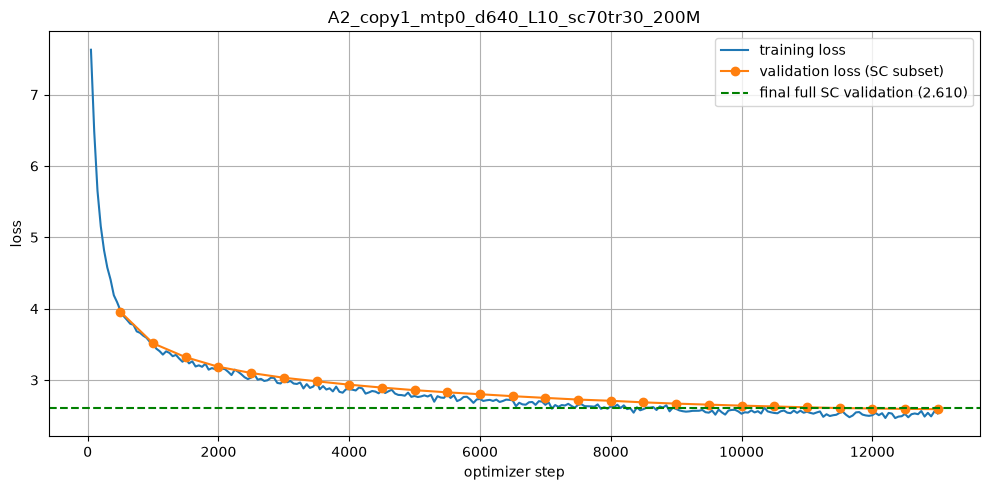

In [22]:
import matplotlib.pyplot as plt
tr = [(h["step"], h["train_loss"]) for h in history]
ev = [(h["step"], h["val_loss"]) for h in history if "val_loss" in h]
plt.figure(figsize=(10, 5))
if tr: plt.plot(*zip(*tr), label="training loss")
if ev: plt.plot(*zip(*ev), marker="o", label="validation loss (SC subset)")
plt.axhline(final_eval["val_loss"], color="green", linestyle="--", label=f"final full SC validation ({final_eval['val_loss']:.3f})")
plt.xlabel("optimizer step"); plt.ylabel("loss"); plt.title(RUN_NAME); plt.grid(True); plt.legend(); plt.tight_layout()
plt.savefig(RUN_DIR / "loss_curve.png", dpi=150); plt.show()

## 7b. What does the copy mechanism copy? (cached, only if copy is on)

On the periodic validation chunks we record, for every predicted token, the copy weight `1 − g`.
We report the overall average, the average when the target token **is present** earlier in the context (copying is possible) vs **absent**, and the tokens with the highest average copy weight.
Interpretable evidence for the report: if the model really learned to copy names, numbers and citations, they should appear at the top.


In [23]:
COPY_STATS = RUN_DIR / "copy_analysis.json"
if not USE_COPY:
    print("copy mechanism off - nothing to analyse")
elif COPY_STATS.exists():
    copy_stats = json.load(open(COPY_STATS)); print("[cache] loaded copy analysis")
else:
    model.eval()
    sum_w = torch.zeros(CFG["vocab_size"], dtype=torch.float64); cnt = torch.zeros(CFG["vocab_size"], dtype=torch.float64)
    present_w, absent_w = [], []
    with torch.no_grad():
        for i in tqdm(val_idx_small, desc="copy analysis"):
            c = get_chunk(sc_val, i).to(device).unsqueeze(0)
            x, y = c[:, :-1], c[:, 1:]
            with torch.autocast(device.type, dtype=AMP_DTYPE, enabled=AMP_DTYPE != torch.float32):
                h = model(x, return_hidden=True)[1]
            w = (1 - torch.sigmoid(model.copy_gate(h).float())).squeeze(-1)[0].double().cpu()   # (T,)
            yt = y[0].cpu()
            sum_w.index_add_(0, yt, w); cnt.index_add_(0, yt, torch.ones_like(w))
            T = x.shape[1]
            present = ((x[0].unsqueeze(0) == y[0].unsqueeze(1)) & torch.ones(T, T, dtype=torch.bool, device=device).tril()).any(1).cpu()
            present_w.append(w[present]); absent_w.append(w[~present])
    pw, aw = torch.cat(present_w), torch.cat(absent_w)
    avg = sum_w / cnt.clamp_min(1)
    top = [int(t) for t in torch.argsort(avg, descending=True) if cnt[t] >= 30][:20]
    copy_stats = {"mean_copy_weight": float(torch.cat([pw, aw]).mean()),
                  "copy_weight_target_in_context": float(pw.mean()), "copy_weight_target_not_in_context": float(aw.mean()),
                  "share_targets_in_context": float(len(pw) / (len(pw) + len(aw))),
                  "top_copied_tokens": [(tokenizer.decode([t]), round(float(avg[t]), 3), int(cnt[t])) for t in top]}
    json.dump(copy_stats, open(COPY_STATS, "w"), indent=1)
if USE_COPY:
    print(f"mean copy weight {copy_stats['mean_copy_weight']:.3f} | when target IS in context {copy_stats['copy_weight_target_in_context']:.3f}"
          f" | when NOT {copy_stats['copy_weight_target_not_in_context']:.3f} | targets present in context: {copy_stats['share_targets_in_context']:.1%}")
    print("Tokens the model copies most (token, avg copy weight, count):")
    for tok, wv, n in copy_stats["top_copied_tokens"]:
        print(f"  {tok!r:20s} {wv:.3f}  ({n})")

copy analysis: 100%|██████████| 256/256 [00:04<00:00, 56.45it/s]


mean copy weight 0.313 | when target IS in context 0.383 | when NOT 0.164 | targets present in context: 68.2%
Tokens the model copies most (token, avg copy weight, count):
  ' SPECIAL'           0.910  (58)
  ' LEAVE'             0.901  (58)
  ' 2024'              0.899  (49)
  ' cms'               0.898  (58)
  'ARY'                0.897  (49)
  ' DI'                0.880  (51)
  ' supervis'          0.878  (36)
  'CIVIL'              0.875  (64)
  '2010'               0.843  (56)
  ' PETITION'          0.835  (74)
  'graduate'           0.823  (34)
  'PW'                 0.784  (132)
  ' labour'            0.783  (65)
  'CC'                 0.781  (46)
  'para'               0.777  (43)
  ' allowance'         0.769  (36)
  ' 2013'              0.760  (60)
  ' Engineers'         0.760  (48)
  ' 2017'              0.759  (36)
  ' NO'                0.757  (237)


## 8. Generation (KV cache, exactly 128 words)

One prompt at a time (no padding problems at all), with a **KV cache**: the prompt is processed once, then each new token costs one tiny forward pass.

Next-token choice, in order:

1. `<|endoftext|>` and `<pad>` are **forbidden** — a continuation must never "end".
2. **Repetition penalty** on every token already in the text (prompt + output).
3. **No-repeat n-gram** (optional): if the last n−1 tokens already appeared earlier followed by token t, t is forbidden now. This directly blocks loops like `27/87, 27/87, 27/87` that broke the baseline. The lookup table is updated incrementally (one entry per new token), so it costs almost nothing.
4. **Greedy** (`temperature = 0`) or **sampling** with temperature and top-p.

**Stopping:** every 16 tokens we decode and count whitespace words; we stop once there are **more than 128** (so the 128th word is complete), then keep exactly the first 128.
**With the copy mechanism:** at each step the vocabulary distribution is mixed with the copy distribution (copy attention over every position so far, added onto those positions' token ids, weighted by 1 − g). The copy keys of all previous positions are cached alongside the KV cache.

**Guarantee:** if a run still has < 128 words after 400 new tokens (a loop of text without spaces), we retry once with a stronger anti-repetition setting. The number of retries is reported.


In [24]:
MAX_NEW_TOKENS = 400
TARGET_WORDS = 128
MAX_PROMPT_TOKENS = CFG["max_seq_len"] - MAX_NEW_TOKENS           # 1136 >= longest test prompt (~982)
BANNED = [EOS_ID, PAD_ID]

@torch.no_grad()
def generate_words(model, prompt_ids, temperature=0.1, top_p=0.95, rep_penalty=1.1, no_repeat_ngram=0, seed=0):
    gen = torch.Generator(device=device).manual_seed(seed)
    seq = list(prompt_ids[-MAX_PROMPT_TOKENS:])
    n_prompt = len(seq)
    seen = torch.zeros(CFG["vocab_size"], dtype=torch.bool, device=device)
    seen[torch.tensor(seq, device=device)] = True
    ngrams = {}
    if no_repeat_ngram:
        n = no_repeat_ngram
        for j in range(len(seq) - n + 1):
            ngrams.setdefault(tuple(seq[j:j + n - 1]), set()).add(seq[j + n - 1])

    cache = [dict() for _ in model.blocks]
    with torch.autocast(device.type, dtype=AMP_DTYPE, enabled=AMP_DTYPE != torch.float32):
        logits, h = model(torch.tensor([seq], device=device), cache=cache, start_pos=0, return_hidden=True)
    logits = logits[0]
    if USE_COPY:
        copy_keys = model.copy_k(h[0]).float()                      # one copy key per position so far
        ids_t = torch.tensor(seq, device=device)
        h_last = h[0, -1]
    words = []
    for t in range(MAX_NEW_TOKENS):
        if USE_COPY:
            logits = model.mix_with_copy(logits, h_last, copy_keys, ids_t)
        logits[BANNED] = -float("inf")
        if rep_penalty != 1.0:
            pen = logits[seen]
            logits[seen] = torch.where(pen > 0, pen / rep_penalty, pen * rep_penalty)
        if no_repeat_ngram and len(seq) >= no_repeat_ngram - 1:
            banned = ngrams.get(tuple(seq[len(seq) - no_repeat_ngram + 1:]))
            if banned:
                logits[list(banned)] = -float("inf")
        if temperature == 0:
            nxt = int(torch.argmax(logits))
        else:
            probs = torch.softmax(logits / temperature, dim=-1)
            sp, si = torch.sort(probs, descending=True)
            cut = torch.cumsum(sp, dim=-1) - sp > top_p          # drop tokens outside the top-p nucleus
            sp[cut] = 0
            nxt = int(si[torch.multinomial(sp / sp.sum(), 1, generator=gen)])
        seq.append(nxt); seen[nxt] = True
        if no_repeat_ngram and len(seq) >= no_repeat_ngram:
            ngrams.setdefault(tuple(seq[-no_repeat_ngram:-1]), set()).add(nxt)
        if (t + 1) % 16 == 0 or t == MAX_NEW_TOKENS - 1:
            words = tokenizer.decode(seq[n_prompt:]).split()
            if len(words) > TARGET_WORDS:
                break
        with torch.autocast(device.type, dtype=AMP_DTYPE, enabled=AMP_DTYPE != torch.float32):
            logits, h = model(torch.tensor([[nxt]], device=device), cache=cache, start_pos=len(seq) - 1, return_hidden=True)
        logits = logits[0]
        if USE_COPY:
            h_last = h[0, -1]
            copy_keys = torch.cat([copy_keys, model.copy_k(h_last).float().unsqueeze(0)])
            ids_t = torch.cat([ids_t, torch.tensor([nxt], device=device)])
    return words[:TARGET_WORDS]

RETRY_CFG = {"temperature": 0.7, "top_p": 0.9, "rep_penalty": 1.2, "no_repeat_ngram": 4}

def continue_prompt(model, prompt_text, dcfg, seed):
    ids = tokenizer.encode(clean_text(prompt_text)).ids
    words = generate_words(model, ids, seed=seed, **dcfg)
    retried = False
    if len(words) < TARGET_WORDS:
        words, retried = generate_words(model, ids, seed=seed + 1, **RETRY_CFG), True
    return " ".join(words), retried

def predict_all(model, prompts, dcfg, desc, limit=None):
    model.eval()
    items = list(prompts.items())[:limit]
    preds, retries = {}, 0
    for k, (pid, rec) in enumerate(tqdm(items, desc=desc)):
        text, retried = continue_prompt(model, rec["text"], dcfg, seed=CFG["seed"] + k)
        preds[str(pid)] = {"text": text}
        retries += retried
    return preds, retries

## 9. Local evaluation (cached)

Three decoding settings on the **new** local evaluation set (200 cleaned SC validation prompts), each with a fixed seed (reproducible), scored by the **official, unchanged** `evaluate_phase1.py`.
Settings compared: the baseline's winner (T=0.1 + repetition penalty 1.1), the same **+ no-repeat 6-gram**, and **greedy + no-repeat 6-gram**.


In [25]:
SWEEP = {
    "T0.1_rep1.1_nrng6":   {"temperature": 0.1, "top_p": 0.95, "rep_penalty": 1.1, "no_repeat_ngram": 6},
    "greedy_rep1.1_nrng6": {"temperature": 0.0, "top_p": 1.0,  "rep_penalty": 1.1, "no_repeat_ngram": 6},
}
local_prompts = json.load(open(EVAL_DIR / "local_eval_prompts.json"))
if ABLATION and not SMOKE_TEST:
    SWEEP = {}                                                   # ablation runs: no generation, validation only
    print("ABLATION run: skipping local generation")
LOCAL_LIMIT = 16 if SMOKE_TEST else None
truth_path = EVAL_DIR / "local_eval_truth.json"
if LOCAL_LIMIT:                                                  # smoke test: evaluator needs matching truth ids
    keep = list(local_prompts)[:LOCAL_LIMIT]
    truth_path = RUN_DIR / "local_truth_subset.json"
    full_truth = json.load(open(EVAL_DIR / "local_eval_truth.json"))
    json.dump({k: full_truth[k] for k in keep}, open(truth_path, "w"))

def run_official_eval(pred_path, truth_path):
    env = dict(os.environ, PYTHONUTF8="1")
    r = subprocess.run([sys.executable, str(EVAL_SCRIPT), "--truth", str(truth_path), "--prediction", str(pred_path)],
                       capture_output=True, text=True, encoding="utf-8", errors="replace", env=env)
    if r.returncode != 0:
        print(r.stderr[-2000:]); return None
    scores = {}
    for line in r.stdout.splitlines():
        key, _, val = line.partition(":")
        if key.strip() in ("BERTScore F1", "ROUGE-L F1", "BLEU-4"):
            scores[key.strip()] = float(val)
    return scores

LOCAL_RESULTS = RUN_DIR / "local_eval_results.json"
local_results = json.load(open(LOCAL_RESULTS)) if LOCAL_RESULTS.exists() else {}
for name, dcfg in SWEEP.items():
    if name in local_results:
        print(f"[cache] {name}: {local_results[name]}")
        continue
    preds, retries = predict_all(model, local_prompts, dcfg, desc=f"local {name}", limit=LOCAL_LIMIT)
    pred_path = RUN_DIR / f"local_pred_{name}.json"
    json.dump(preds, open(pred_path, "w"), indent=1)
    scores = run_official_eval(pred_path, truth_path)
    local_results[name] = {**(scores or {}), "retries": retries}
    json.dump(local_results, open(LOCAL_RESULTS, "w"), indent=1)      # saved after EACH setting
    print(f"{name}: {local_results[name]}")

local T0.1_rep1.1_nrng6: 100%|██████████| 200/200 [06:52<00:00,  2.06s/it]


T0.1_rep1.1_nrng6: {'BERTScore F1': 0.826257, 'ROUGE-L F1': 0.193438, 'BLEU-4': 0.044223, 'retries': 1}


local greedy_rep1.1_nrng6: 100%|██████████| 200/200 [06:29<00:00,  1.95s/it]


greedy_rep1.1_nrng6: {'BERTScore F1': 0.826779, 'ROUGE-L F1': 0.198242, 'BLEU-4': 0.046758, 'retries': 1}


## 10. Test predictions → checks → submission.zip (cached)

Uses the decoding setting with the best local BERTScore. Checks before zipping: same IDs as `test.json`, no empty text, **every prediction exactly 128 words**.


In [26]:
from huggingface_hub import hf_hub_download
test_data = json.load(open(hf_hub_download("Exploration-Lab/CS-781-Capstone", "Phase_1_Pretraining/Test/test.json",
                                           repo_type="dataset"), encoding="utf-8"))
PRED_PATH, ZIP_PATH = RUN_DIR / "prediction.json", RUN_DIR / "submission.zip"

if ABLATION and not SMOKE_TEST:
    print("ABLATION run: no test predictions")
elif ZIP_PATH.exists():
    print("[cache] submission already exists:", ZIP_PATH)
else:
    best = max(local_results, key=lambda n: local_results[n].get("BERTScore F1", -1))
    print("Decoding:", best, SWEEP[best])
    preds, retries = predict_all(model, test_data, SWEEP[best], desc="test", limit=20 if SMOKE_TEST else None)
    wc = [len(p["text"].split()) for p in preds.values()]
    print(f"{len(preds)} predictions | words min={min(wc)} max={max(wc)} | not 128: {sum(w != 128 for w in wc)} | retries: {retries}")
    if not SMOKE_TEST:
        assert set(preds) == set(test_data), "ID mismatch with test.json"
        assert all(p["text"].strip() for p in preds.values()), "empty prediction"
        json.dump(preds, open(PRED_PATH, "w"), indent=1)
        with zipfile.ZipFile(ZIP_PATH, "w", compression=zipfile.ZIP_DEFLATED) as z:
            z.write(PRED_PATH, arcname="prediction.json")
        print(zipfile.ZipFile(ZIP_PATH).namelist(), "->", ZIP_PATH)

Decoding: greedy_rep1.1_nrng6 {'temperature': 0.0, 'top_p': 1.0, 'rep_penalty': 1.1, 'no_repeat_ngram': 6}


test: 100%|██████████| 1000/1000 [31:29<00:00,  1.89s/it]

1000 predictions | words min=128 max=128 | not 128: 0 | retries: 2
['prediction.json'] -> c:\Users\Atharva\Desktop\Course Sem 1\LLM\Capstone Project\checkpoints\phase1\A2_copy1_mtp0_d640_L10_sc70tr30_200M\submission.zip


## 11. Log the experiment (once per run)


In [27]:
def logged_runs():
    # run names already in the log; skips blank or broken lines instead of crashing
    runs = set()
    if EXP_LOG.exists():
        for line in open(EXP_LOG, encoding="utf-8"):
            line = line.strip()
            if not line:
                continue
            try:
                runs.add(json.loads(line).get("run"))
            except json.JSONDecodeError:
                pass
    return runs

already = RUN_NAME in logged_runs()
if already or SMOKE_TEST:
    print("Not logging (already logged or smoke test).")
else:
    t = json.load(open(RUN_DIR / "train_time.json")) if (RUN_DIR / "train_time.json").exists() else {}
    entry = {"run": RUN_NAME, "time": time.strftime("%Y-%m-%d %H:%M"), "arch": CFG["arch"],
             "use_copy": USE_COPY, "use_mtp": USE_MTP, "ablation": ABLATION,
             "params_M": round(n_params / 1e6, 2), "train_tokens": CFG["train_tokens"], "mix": CFG["mix"],
             "ctx": CFG["max_seq_len"], "tokens_per_step": tokens_per_step, "lr": CFG["lr"],
             "train_hours": t.get("train_hours_this_session"), **final_eval, "local_eval": local_results,
             "copy_analysis": copy_stats if USE_COPY else None}
    with open(EXP_LOG, "a") as f:
        f.write(json.dumps(entry) + "\n")
    print(json.dumps(entry, indent=1))

{
 "run": "A2_copy1_mtp0_d640_L10_sc70tr30_200M",
 "time": "2026-10-03 05:07",
 "arch": "A2",
 "use_copy": true,
 "use_mtp": false,
 "ablation": false,
 "params_M": 70.22,
 "train_tokens": 200000000,
 "mix": {
  "sc": 0.7,
  "tribunals": 0.3
 },
 "ctx": 1536,
 "tokens_per_step": 15360,
 "lr": 0.0003,
 "train_hours": 3.102239438229137,
 "val_loss": 2.6104828449005777,
 "perplexity": 13.605618669678506,
 "bits_per_char": 0.7733263288669018,
 "val_tokens": 2815488,
 "local_eval": {
  "T0.1_rep1.1_nrng6": {
   "BERTScore F1": 0.826257,
   "ROUGE-L F1": 0.193438,
   "BLEU-4": 0.044223,
   "retries": 1
  },
  "greedy_rep1.1_nrng6": {
   "BERTScore F1": 0.826779,
   "ROUGE-L F1": 0.198242,
   "BLEU-4": 0.046758,
   "retries": 1
  }
 },
 "copy_analysis": {
  "mean_copy_weight": 0.3132161079826498,
  "copy_weight_target_in_context": 0.3826160120948412,
  "copy_weight_target_not_in_context": 0.16411575431114275,
  "share_targets_in_context": 0.6823806762695312,
  "top_copied_tokens": [
   [
    

## 12. Ablation table (reads every finished 40M run of this notebook)

Run the notebook four times with `ABLATION = True` and the four flag combinations; this cell collects their saved results. Lower is better for loss and bits/char.


In [28]:
rows = []
for d in sorted((PROJECT_ROOT / "checkpoints" / "phase1").glob("A2_copy*_mtp*_40M")):
    fe, cf = d / "final_eval.json", d / "config.json"
    if fe.exists() and cf.exists():
        e, c = json.load(open(fe)), json.load(open(cf))
        ca = json.load(open(d / "copy_analysis.json")) if (d / "copy_analysis.json").exists() else {}
        rows.append((c["use_copy"], c["use_mtp"], e["val_loss"], e["bits_per_char"], ca.get("mean_copy_weight")))
print(f"{'copy':>5s} {'MTP':>4s} {'val loss':>9s} {'bits/char':>10s} {'copy weight':>12s}")
for cp, mt, vl, bpc, cw in sorted(rows):
    print(f"{'yes' if cp else 'no':>5s} {'yes' if mt else 'no':>4s} {vl:9.4f} {bpc:10.4f} {('%.3f' % cw) if cw is not None else '-':>12s}")
if not rows:
    print("No finished ablation runs yet.")

 copy  MTP  val loss  bits/char  copy weight
   no   no    3.4753     1.0295            -
   no  yes    3.4545     1.0233            -
  yes   no    3.1190     0.9240        0.399
  yes  yes    3.1268     0.9263        0.342


## Viva check

1. Write the copy-mixture probability. What do `g`, `a_tj` and `[x_j = y]` mean?
2. Why don't we build the full 32,000-token copy distribution during training?
3. Why is there no information leak in the copy attention?
4. Why initialise the gate bias to +2?
5. What does the MTP head predict, why is its loss weighted 0.3, and why is it dropped at inference?
6. Why do the ablation runs compare next-token loss only (not including the MTP loss)?
7. What would you conclude if copy improves loss but the copy weight is high even when the target is NOT in the context?
